# InvertML: the complete project in one notebook

Every Python module of `src/` combined into one notebook, in dependency order, followed by cells that run the whole pipeline from the raw data to the final comparison.

**Data needed:** the HKUST dataset unzipped in `data/raw/Dataset/` and the 16 GPVS-Faults CSV files in `data/raw/GPVS-Faults/` (see the README).

**Outputs:** the same files as the scripts: `data/processed/`, `reports/tables/`, `reports/figures/` and `results/results.csv`.

**Run time:** about 15-25 minutes for everything on a laptop. Data preparation and the model table only need to run once; set `RUN_DATA_PREPARATION = False` below to skip them afterwards.

The code is copied from `src/` (the source of truth, used by the unit tests); only names that clash between modules were renamed (for example `main()` becomes `rf_main()`), and figures are shown inline as well as saved.

**Contents**

1. Shared settings (`src/common.py`)
2. Stage 3: Data preparation (A1) (`src/prepare_data.py`)
3. Stages 4 and 7: Cleaning, target, features and splits (`src/dataset.py`)
4. Stage 11: Shared evaluation framework (B2) (`src/evaluate.py`)
5. Stage 6: Exploratory data analysis (all members) (`src/eda.py`)
6. Stages 4, 5 and 7: Decision studies (`src/studies.py`)
7. Stage 8 baselines and Track T1 linear models (A1) (`src/models/linear.py`)
8. Track T2: Random Forest (A2) (`src/models/rf.py`)
9. Track T3: XGBoost (B1) (`src/models/xgb.py`)
10. Track T4: Multilayer perceptron (B2) (`src/models/mlp.py`)
11. Track T5: Isolation Forest anomaly detection (Pairs A and B) (`src/models/iforest.py`)
12. Stage 11: Final comparison of every model (`src/compare.py`)
13. Run the whole pipeline

## Imports

In [1]:
%matplotlib inline
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import yaml
import re
import numpy as np
import pandas as pd
import rdflib
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (f1_score, mean_absolute_error, mean_squared_error,
                             precision_score, r2_score, recall_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
import shap
from xgboost import XGBClassifier, XGBRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.ensemble import IsolationForest
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.pipeline import make_pipeline as sk_make_pipeline
from IPython.display import display

## 1. Shared settings

*From `src/common.py`.*

```text
Shared settings used by every script: config, folders, plot helper.
```

In [2]:

# repo root: this notebook lives in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CONFIG = yaml.safe_load(open(ROOT / "configs" / "config.yaml", encoding="utf-8"))

RAW = ROOT / CONFIG["paths"]["raw"]
PROCESSED = ROOT / CONFIG["paths"]["processed"]
TABLES = ROOT / "reports" / "tables"
FIGURES = ROOT / "reports" / "figures"
RESULTS = ROOT / "results"
for folder in (PROCESSED, TABLES, FIGURES, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

SEED = CONFIG["random_state"]
CLASSES = ["Healthy", "Warning", "Faulty"]

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def save_figure(fig, name):
    """Save a figure to reports/figures/<name>.png and close it."""
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=130)
    display(fig)                 # show inline in the notebook
    plt.close(fig)
    print(f"  saved figure {name}.png")

## 2. Stage 3: Data preparation (A1)

*From `src/prepare_data.py`.*

```text
Stage 3: data preparation (A1).

Raw HKUST files -> one clean 15-minute table, data/processed/hkust_15min.parquet

1. Metadata: read the Brick .ttl graph with SPARQL -> one row per inverter
2. Inverters: read the 44 inverter CSVs (AC power, DC voltage), 5-min -> 15-min
3. Weather: read irradiance, temperature, humidity, wind, 1-min -> 15-min
4. Build the full 06:00-17:45 grid, merge, correct the irradiance sensor change
5. Gap analysis + 70 % daylight-coverage filter + before/after summary

Times are Hong Kong local time (no daylight saving).
Run: python -m src.prepare_data
```

In [3]:
DATASET = RAW / "Dataset"
TTL_FILE = DATASET / "Metadata" / "PV generation system metadata.ttl"
INVERTER_DIR = (DATASET / "Time series dataset" / "PV generation dataset"
                / "PV stations with panel level optimizer" / "Inverter level dataset")
WEATHER_DIR = DATASET / "Time series dataset" / "Meteorological dataset"

# weather folder -> (column in the raw file, our column name)
WEATHER = {"Irradiance": ("Irradiance (W/m2)", "irradiance_wm2"),
           "Temperature": ("Temp (Degree Celsius)", "temp_c"),
           "Relative Humidity": ("RH (%)", "rh_pct"),
           "Wind": ("Wind Speed (m/s)", "wind_speed_ms")}

# The raw files mix two timestamp formats; anything else is an error.
TIME_FORMATS = ["%Y-%m-%d %H:%M:%S", "%Y/%m/%d %H:%M"]

# One syntax error in the raw .ttl (Zone D block) is fixed in memory only.
TTL_TYPO = ("brick:value 68.62 ] .\n    ext:azimuth", "brick:value 68.62 ] ;\n    ext:azimuth")
# One CSV file name does not match its Brick name.
NAME_FIX = {"indoor_sports_centre_inverter": "indoor_sport_center_inverter"}

SPARQL = """
PREFIX brick: <https://brickschema.org/schema/Brick#>
PREFIX ext:   <https://www.HKUST_PV_System.com/schema/BrickExtension#>
SELECT ?station ?inverter ?altitude ?azimuth ?tilt ?model ?panels ?panel_w WHERE {
  ?station a brick:PV_Generation_System ; brick:hasPart ?inverter .
  ?inverter a brick:Inverter ; brick:hasPart ?panel .
  ?panel ext:number/brick:value ?panels ; ext:ratedPowerOutput/brick:value ?panel_w .
  OPTIONAL { ?station ext:altitude/brick:value ?altitude }
  OPTIONAL { ?station ext:azimuth/brick:value ?azimuth }
  OPTIONAL { ?station ext:tiltAngle/brick:value ?tilt }
  OPTIONAL { ?inverter ext:module/brick:value ?model }
}
"""

FIRST_BIN, LAST_BIN = "06:00", "17:45"   # loggers only record 06:00-17:59
SENSOR_CHANGE = pd.Timestamp(CONFIG["irradiance_sensor_change"])


def clean_name(name):
    """'SQ Apartment1-12_Inverter' -> 'sq_apartment1_12_inverter'."""
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")


def parse_time(values):
    for fmt in TIME_FORMATS:
        try:
            return pd.to_datetime(values, format=fmt)
        except ValueError:
            pass
    raise ValueError("unknown timestamp format")


# ---------------------------------------------------------------- 1. metadata

def read_metadata():
    """One row per inverter: station, capacity (kWp), tilt, orientation, altitude."""
    text = TTL_FILE.read_text(encoding="utf-8").replace("\r\n", "\n").replace(*TTL_TYPO)
    graph = rdflib.Graph().parse(data=text, format="turtle")
    rows = [{key: (value.toPython() if value is not None else None)
             for key, value in row.asdict().items()} for row in graph.query(SPARQL)]
    panels = pd.DataFrame(rows)
    panels["kwp"] = panels["panels"].astype(float) * panels["panel_w"].astype(float) / 1000

    # an inverter can drive several panel groups: add up their capacity
    meta = panels.groupby("inverter").agg(
        station_id=("station", "first"), capacity_kwp=("kwp", "sum"),
        altitude_m=("altitude", "first"), azimuth=("azimuth", "first"),
        tilt=("tilt", "first"), inverter_model=("model", "first")).reset_index()
    for col in ["inverter", "station_id"]:
        meta[col] = meta[col].astype(str).str.split("#").str[-1]
    meta["altitude_m"] = meta["altitude_m"].astype(float)

    # tilt like "10deg", "0/15deg" (two roof parts: use the average) or "Mixed" (use 5)
    tilt = meta.pop("tilt").str.replace("deg", "")
    meta["tilt_deg"] = [5.0 if t == "Mixed" else np.mean([float(x) for x in t.split("/")])
                        for t in tilt]
    # orientation like "0deg", "90/-90deg" or "Mixed": flag arrays facing several ways
    meta["multi_orientation"] = meta["azimuth"].str.contains("/|Mixed").astype(int)

    # keep the 44 inverters that have a CSV file, named after the file
    files = {NAME_FIX.get(clean_name(f.stem), clean_name(f.stem)): clean_name(f.stem)
             for f in INVERTER_DIR.glob("*.csv")}
    meta["key"] = meta.pop("inverter").map(clean_name)
    missing = set(files) - set(meta["key"])
    if missing:
        raise ValueError(f"CSV files without metadata: {missing}")
    meta = meta[meta["key"].isin(files)]
    meta.insert(0, "inverter_id", meta.pop("key").map(files))
    return meta.sort_values("inverter_id").reset_index(drop=True)


# ---------------------------------------------------------------- 2. inverters

def read_inverters():
    """All 44 inverter files, averaged to 15 minutes.
    n_valid_5min = how many of the three 5-min readings were present (0-3)."""
    frames = []
    for f in sorted(INVERTER_DIR.glob("*.csv")):
        df = pd.read_csv(f, usecols=["Time", "totalActivePower(W)", "dcVoltage(V)"],
                         na_values=["NA"])
        df = df.rename(columns={"Time": "time", "totalActivePower(W)": "ac_power_w",
                                "dcVoltage(V)": "dc_voltage_v"})
        df["time"] = parse_time(df["time"])
        df["inverter_id"] = clean_name(f.stem)
        frames.append(df)
    raw = pd.concat(frames, ignore_index=True)

    raw["time"] = raw["time"].dt.floor("15min")          # 10:00, 10:05, 10:10 -> 10:00
    grouped = raw.groupby(["inverter_id", "time"])
    out = grouped[["ac_power_w", "dc_voltage_v"]].mean()
    out["n_valid_5min"] = grouped["ac_power_w"].count()
    return raw, out.reset_index()


# ---------------------------------------------------------------- 3. weather

def read_weather():
    """Four weather variables for 2021-2023, averaged to 15 minutes."""
    columns = []
    for folder, (raw_name, name) in WEATHER.items():
        parts = [pd.read_csv(WEATHER_DIR / folder / f"{folder}_{year}.csv",
                             usecols=["Time", raw_name], na_values=["NA"])
                 for year in (2021, 2022, 2023)]
        df = pd.concat(parts).rename(columns={"Time": "time", raw_name: name})
        df["time"] = parse_time(df["time"]).dt.floor("15min")
        columns.append(df.groupby("time")[name].mean())
    return pd.concat(columns, axis=1).reset_index()


# ---------------------------------------------------------------- 4. grid + merge

def full_grid(inv15):
    """Every 15-min bin from 06:00 to 17:45, from each inverter's first day to the
    end of 2023, so that gaps become visible rows with n_valid_5min = 0."""
    end = pd.Timestamp(CONFIG["split"]["test_end"]) + pd.Timedelta("17:45:00")
    grids = []
    for inverter, start in inv15.groupby("inverter_id")["time"].min().items():
        times = pd.date_range(start, end, freq="15min")
        times = times[(times.strftime("%H:%M") >= FIRST_BIN) & (times.strftime("%H:%M") <= LAST_BIN)]
        grids.append(pd.DataFrame({"inverter_id": inverter, "time": times}))
    grid = pd.concat(grids, ignore_index=True)
    full = grid.merge(inv15, on=["inverter_id", "time"], how="left")
    full["n_valid_5min"] = full["n_valid_5min"].fillna(0).astype(int)
    return full


def correct_sensor(df):
    """The irradiance sensor reads about 1.75x higher from 2023-02-14 (EDA).
    Factor = median over Feb-Dec of (2023 median PR / same month 2022 median PR).
    Irradiance from that day is multiplied by the factor; the raw value is kept."""
    ok = df["ac_power_w"].notna() & (df["irradiance_wm2"] >= 100)
    pr = (df["ac_power_w"] / (df["irradiance_wm2"] * df["capacity_kwp"])).where(ok)
    year, month = df["time"].dt.year, df["time"].dt.month
    rows = []
    for m in range(SENSOR_CHANGE.month, 13):
        before = pr[(year == SENSOR_CHANGE.year - 1) & (month == m)].median()
        after = pr[(year == SENSOR_CHANGE.year) & (month == m) & (df["time"] >= SENSOR_CHANGE)].median()
        rows.append({"month": m, "pr_2022": round(before, 4), "pr_2023": round(after, 4),
                     "ratio": round(after / before, 4)})
    table = pd.DataFrame(rows)
    factor = table["ratio"].median()
    df["irradiance_raw_wm2"] = df["irradiance_wm2"]
    after_change = df["time"] >= SENSOR_CHANGE
    df.loc[after_change, "irradiance_wm2"] *= factor
    return df, table, factor


# ---------------------------------------------------------------- 5. gaps

def gap_tables(df):
    """Missing bin = no valid power reading. Only daylight bins count
    (irradiance >= 50 W/m2), so the inverters' dawn sleep is not a gap."""
    day = df[df["irradiance_wm2"] >= CONFIG["daylight_irradiance_wm2"]]
    missing = day["n_valid_5min"].eq(0)
    by_month = (missing.groupby([day["inverter_id"], day["time"].dt.to_period("M").astype(str)])
                .agg(["size", "mean"]).reset_index())
    by_month.columns = ["inverter_id", "month", "daylight_bins", "missing_share"]
    coverage = (1 - missing.groupby(day["inverter_id"]).mean()).rename("coverage").reset_index()
    coverage["kept"] = coverage["coverage"] >= CONFIG["min_daylight_coverage"]
    return by_month.round(4), coverage.sort_values("coverage").round(4)


def prepare_data_main():
    summary = []
    step = lambda name, d: summary.append({"step": name, "rows": len(d), "columns": d.shape[1],
                                           "inverters": d["inverter_id"].nunique()})

    print("1. metadata")
    meta = read_metadata()
    meta.to_parquet(PROCESSED / "inverter_metadata.parquet", index=False)
    print(f"   {len(meta)} inverters at {meta['station_id'].nunique()} stations")

    print("2. inverters")
    raw, inv15 = read_inverters()
    step("raw 5-min inverter rows", raw)
    step("averaged to 15 min", inv15)

    print("3. weather")
    weather = read_weather()

    print("4. full grid, merge, sensor correction")
    df = full_grid(inv15)
    step("full 06:00-17:45 grid", df)
    df = df.merge(weather, on="time", how="left").merge(meta, on="inverter_id", how="left")
    step("merged with weather + metadata", df)
    df, correction, factor = correct_sensor(df)
    correction.to_csv(TABLES / "irradiance_correction.csv", index=False)
    print(f"   irradiance from {SENSOR_CHANGE.date()} multiplied by {factor:.3f}")

    print("5. gaps and coverage")
    by_month, coverage = gap_tables(df)
    by_month.to_csv(TABLES / "gaps_by_inverter_month.csv", index=False)
    coverage.to_csv(TABLES / "coverage_by_inverter.csv", index=False)
    df = df[df["inverter_id"].isin(coverage.loc[coverage["kept"], "inverter_id"])]
    step("coverage filter (>= 70 %)", df)
    print(f"   lowest coverage {coverage['coverage'].min():.1%}, "
          f"dropped {int((~coverage['kept']).sum())} inverters")

    float_cols = df.select_dtypes("float64").columns
    df[float_cols] = df[float_cols].astype("float32")
    df.to_parquet(PROCESSED / "hkust_15min.parquet", index=False)
    pd.DataFrame(summary).to_csv(TABLES / "prep_summary.csv", index=False)
    print(pd.DataFrame(summary).to_string(index=False))

## 3. Stages 4 and 7: Cleaning, target, features and splits

*From `src/dataset.py`.*

```text
Stages 4 and 7: cleaning, health-score target, features and splits.

hkust_15min.parquet -> data/processed/model_table.parquet, the one table that
every model reads. One row = one inverter at one 15-minute time t.

Target    health_lead : health score one hour later, Health(t + 1 h)
          status_lead : Healthy (>= 90) / Warning (70-90) / Faulty (< 70)
Features  everything known at time t (see FEATURES below)

Run: python -m src.dataset
```

In [4]:
DERATE = 0.78            # expected power = irradiance x capacity x 0.78
HEALTH_MIN_IRR = 100     # no health score below 100 W/m2 (too dark to judge)
HEALTHY, FAULTY = 90, 70

CANDIDATE_FEATURES = [
    # current state (A1)
    "health_now", "n_valid_5min", "minutes_offline_24h",
    # weather
    "irradiance_wm2", "temp_c", "rh_pct", "wind_speed_ms",
    # time of day / year (B2)
    "hour_sin", "hour_cos", "day_sin", "day_cos",
    # array metadata from the Brick file (B2)
    "capacity_kwp", "tilt_deg", "altitude_m", "multi_orientation",
    # physics: compare with other inverters and with own past (B1)
    "peer_dev", "self_dev_30d",
    # recent history (A2)
    "health_lag_15m", "health_lag_1d", "health_mean_4h", "peer_dev_mean_4h",
]
# Feature selection (Stage 7): multi_orientation is almost the same as tilt_deg
# (r = 0.97 on train, see reports/tables/study_correlated_features.csv), so it is dropped.
DROPPED = ["multi_orientation"]
FEATURES = [f for f in CANDIDATE_FEATURES if f not in DROPPED]


# ---------------------------------------------------------------- Stage 4

def clean(df):
    """Physical rules. Impossible values become missing; real extremes stay.
    - power below 0 or above 1.1 x capacity is a sensor error
    - irradiance below 0 or above 1500 W/m2 is a sensor error
    - offline = no valid power reading in the bin (kept as an event, not filled in)"""
    df = df.copy()
    bad_power = (df["ac_power_w"] < 0) | (df["ac_power_w"] > 1.1 * df["capacity_kwp"] * 1000)
    df.loc[bad_power, "ac_power_w"] = np.nan
    bad_irr = (df["irradiance_wm2"] < 0) | (df["irradiance_wm2"] > 1500)
    df.loc[bad_irr, "irradiance_wm2"] = np.nan
    df["is_offline"] = (df["ac_power_w"].isna() | (df["n_valid_5min"] == 0)).astype(int)
    df.loc[df["is_offline"] == 1, "ac_power_w"] = np.nan
    return df


# ---------------------------------------------------------------- Stage 7: target

def health_score(ac_power_w, irradiance_wm2, capacity_kwp):
    """Health = actual power / expected power x 100, limited to 0-100.
    Missing when it is too dark (< 100 W/m2) or the power reading is missing."""
    expected = np.maximum(irradiance_wm2 / 1000 * capacity_kwp * 1000 * DERATE, 100)
    health = np.clip(100 * ac_power_w / expected, 0, 100)
    return health.where(irradiance_wm2 >= HEALTH_MIN_IRR)


def status(health):
    """Health score -> Healthy / Warning / Faulty."""
    return np.select([health >= HEALTHY, health >= FAULTY], ["Healthy", "Warning"], "Faulty")


# ---------------------------------------------------------------- Stage 7: features

def past_rolling(df, column, window, how):
    """Per inverter: statistic of `column` over the window BEFORE t (t excluded)."""
    out = pd.Series(np.nan, index=df.index)
    for _, g in df.groupby("inverter_id"):
        series = g.set_index("time")[column]
        rolled = series.rolling(window, closed="left", min_periods=1).agg(how)
        out.loc[g.index] = rolled.to_numpy()
    return out


def value_at(df, column, shift):
    """Value of `column` for the same inverter at time t + shift (exact time match).
    shift = -15 min gives the previous bin; +1 h gives the value one hour later.
    If that exact time is missing the result is missing (no jumping over gaps)."""
    other = df[["inverter_id", "time", column]].rename(columns={column: "_value"})
    other["time"] -= shift
    return df[["inverter_id", "time"]].merge(other, on=["inverter_id", "time"], how="left")["_value"].to_numpy()


def add_features(df):
    t = df["time"]
    df["health_now"] = health_score(df["ac_power_w"], df["irradiance_wm2"], df["capacity_kwp"])

    # time of day and day of year as points on a circle (23:45 is next to 00:00)
    hour = t.dt.hour + t.dt.minute / 60
    df["hour_sin"], df["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
    day = t.dt.dayofyear
    df["day_sin"], df["day_cos"] = np.sin(2 * np.pi * day / 365.25), np.cos(2 * np.pi * day / 365.25)

    # performance ratio, and how far each inverter is from the campus median at the same time
    df["pr"] = (df["ac_power_w"] / (df["irradiance_wm2"] * df["capacity_kwp"])).where(
        df["irradiance_wm2"] >= HEALTH_MIN_IRR)
    campus = df.groupby("time")["pr"].transform("median")
    df["peer_dev"] = ((df["pr"] - campus) / campus).clip(-1, 2)

    # history of the same inverter (only the past is used)
    df["health_lag_15m"] = value_at(df, "health_now", pd.Timedelta("-15min"))
    df["health_lag_1d"] = value_at(df, "health_now", pd.Timedelta("-1D"))
    df["health_mean_4h"] = past_rolling(df, "health_now", "4h", "mean")
    df["peer_dev_mean_4h"] = past_rolling(df, "peer_dev", "4h", "mean")
    df["self_dev_30d"] = df["health_now"] - past_rolling(df, "health_now", "30D", "median")

    # outage history: minutes offline in daylight during the past 24 hours
    df["offline_daylight"] = df["is_offline"] * (df["irradiance_wm2"] >= CONFIG["daylight_irradiance_wm2"])
    df["minutes_offline_24h"] = 15 * past_rolling(df, "offline_daylight", "24h", "sum").fillna(0)
    return df


def add_target(df):
    """health_lead = health of the same inverter exactly one hour later."""
    df["health_lead"] = value_at(df, "health_now", pd.Timedelta("1h"))
    return df


# ---------------------------------------------------------------- splits

def add_split(df):
    """train <= 2022-06-30 < val <= 2022-12-31 < test (2023).
    The six unseen inverters only appear in 2023 and never in train/val."""
    s = CONFIG["split"]
    df["split"] = np.select([df["time"] < pd.Timestamp(s["train_end"]) + pd.Timedelta("1D"),
                             df["time"] < pd.Timestamp(s["val_end"]) + pd.Timedelta("1D")],
                            ["train", "val"], "test")
    df["unseen"] = df["inverter_id"].isin(CONFIG["unseen_stations"])
    return df[~(df["unseen"] & (df["split"] != "test"))]


def build():
    df = pd.read_parquet(PROCESSED / "hkust_15min.parquet")
    df = df.sort_values(["inverter_id", "time"]).reset_index(drop=True)
    df = add_features(clean(df))
    df = add_target(df)
    rows = df.dropna(subset=["health_now", "health_lead"]).copy()
    rows["status_now"] = status(rows["health_now"])
    rows["status_lead"] = status(rows["health_lead"])
    rows = add_split(rows)

    keep = ["inverter_id", "station_id", "time", "split", "unseen", "ac_power_w", "pr",
            "health_lead", "status_lead", "status_now"] + CANDIDATE_FEATURES
    rows = rows[list(dict.fromkeys(keep))].reset_index(drop=True)
    rows.to_parquet(PROCESSED / "model_table.parquet", index=False)
    print(rows.groupby("split").size().to_string())
    print(f"unseen test rows: {rows['unseen'].sum():,}")
    return rows


def load():
    return pd.read_parquet(PROCESSED / "model_table.parquet")

## 4. Stage 11: Shared evaluation framework (B2)

*From `src/evaluate.py`.*

```text
Stage 11: shared evaluation (B2 lead), used by every model.

- metrics: RMSE / MAE / R2 for the health score, macro-F1 and Faulty recall for the status
- evaluation sets: train, val, test, test before / after the 2023-02-14 sensor change,
  and unseen inverters (2023 rows of the six held-out inverters)
- run_model(): the same recipe for every model family (Stages 9, 10, 11)
    1. fit with default settings
    2. tune on the training period with a 3-fold TimeSeriesSplit (no shuffling)
    3. score the tuned model on every evaluation set
    4. permutation importance (explainability) and worst predictions (failure cases)
    5. save tables and update results/results.csv
```

In [5]:
SENSOR_CHANGE = pd.Timestamp(CONFIG["irradiance_sensor_change"])
RESULTS_FILE = RESULTS / "results.csv"


# ---------------------------------------------------------------- data

def evaluation_sets(df=None):
    """Named subsets of the model table. Train is sorted by time for TimeSeriesSplit."""
    df = load() if df is None else df
    test = df[df["split"] == "test"]
    return {
        "train": df[df["split"] == "train"].sort_values("time"),
        "val": df[df["split"] == "val"],
        "test": test,
        "test_before_14feb": test[test["time"] < SENSOR_CHANGE],
        "test_after_14feb": test[test["time"] >= SENSOR_CHANGE],
        "unseen": test[test["unseen"]],
    }


# ---------------------------------------------------------------- metrics

def regression_scores(y_true, y_pred):
    return {"rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3),
            "mae": round(float(mean_absolute_error(y_true, y_pred)), 3),
            "r2": round(float(r2_score(y_true, y_pred)), 3)}


def classification_scores(y_true, y_pred):
    faulty_true, faulty_pred = np.asarray(y_true) == "Faulty", np.asarray(y_pred) == "Faulty"
    return {"macro_f1": round(float(f1_score(y_true, y_pred, average="macro")), 3),
            "faulty_recall": round(float(recall_score(faulty_true, faulty_pred)), 3),
            "faulty_precision": round(float(precision_score(faulty_true, faulty_pred,
                                                            zero_division=0)), 3)}


def score_all(task, predict, sets):
    """One row per evaluation set. `predict(part)` returns predictions for that part."""
    rows = []
    for name, part in sets.items():
        if task == "regression":
            scores = regression_scores(part["health_lead"], predict(part))
        else:
            scores = classification_scores(part["status_lead"], predict(part))
        rows.append({"set": name, "rows": len(part), **scores})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- results file

def save_results(owner, model, task, table):
    """Replace this model's rows in results/results.csv (no duplicates on re-runs)."""
    new = table.assign(owner=owner, model=model, task=task)
    if RESULTS_FILE.exists():
        old = pd.read_csv(RESULTS_FILE)
        old = old[~((old["model"] == model) & (old["task"] == task))]
        new = pd.concat([old, new], ignore_index=True)
    first = ["owner", "model", "task", "set", "rows"]
    new[first + [c for c in new.columns if c not in first]].to_csv(RESULTS_FILE, index=False)


# ---------------------------------------------------------------- models

def make_pipeline(model, scale):
    """Fill missing features with the training median, scale if the model needs it."""
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)


def fit(pipe, X, y, task):
    """Classifiers get balanced sample weights (Stage 5 decision): every class
    counts equally, so the rare Faulty class is not ignored."""
    if task == "classification":
        return pipe.fit(X, y, model__sample_weight=compute_sample_weight("balanced", y))
    return pipe.fit(X, y)


def tune(pipe, grid, train, task, tune_rows):
    """GridSearch with a 3-fold TimeSeriesSplit on (a time-ordered sample of) train."""
    if tune_rows and len(train) > tune_rows:
        train = train.sample(tune_rows, random_state=SEED).sort_values("time")
    target = "health_lead" if task == "regression" else "status_lead"
    scoring = "neg_root_mean_squared_error" if task == "regression" else "f1_macro"
    search = GridSearchCV(pipe, grid, cv=TimeSeriesSplit(n_splits=3), scoring=scoring, n_jobs=-1)
    if task == "classification":
        weights = compute_sample_weight("balanced", train[target])
        search.fit(train[FEATURES], train[target], model__sample_weight=weights)
    else:
        search.fit(train[FEATURES], train[target])
    return search.best_params_


def run_model(owner, name, task, model, grid, scale=False, tune_rows=None):
    """Default fit -> tuning -> tuned fit -> scores, importance, failure cases."""
    print(f"\n{name} ({task})")
    sets = evaluation_sets()
    train = sets["train"]
    target = "health_lead" if task == "regression" else "status_lead"
    X, y = train[FEATURES], train[target]

    default = fit(make_pipeline(clone(model), scale), X, y, task)
    best_params = tune(make_pipeline(clone(model), scale), grid, train, task, tune_rows)
    tuned = fit(make_pipeline(clone(model), scale).set_params(**best_params), X, y, task)
    print(f"  best settings: {best_params}")

    scores = score_all(task, lambda part: tuned.predict(part[FEATURES]), sets)
    default_vs_tuned = pd.concat([
        score_all(task, lambda part: m.predict(part[FEATURES]),
                  {"val": sets["val"], "test": sets["test"]}).assign(version=v)
        for v, m in [("default", default), ("tuned", tuned)]])
    default_vs_tuned["tuned_settings"] = str(best_params)

    tag = f"{name.lower().replace(' ', '_')}_{task}"
    scores.to_csv(TABLES / f"{tag}_scores.csv", index=False)
    default_vs_tuned.to_csv(TABLES / f"{tag}_default_vs_tuned.csv", index=False)
    importance(tuned, sets["val"], task).to_csv(TABLES / f"{tag}_importance.csv")
    if task == "regression":
        failure_cases(tuned, sets["test"]).to_csv(TABLES / f"{tag}_failures.csv", index=False)
    save_results(owner, name, task, scores)
    print(scores.to_string(index=False))
    return tuned, scores


def importance(model, val, task, rows=5000):
    """Permutation importance: how much the validation score drops when one
    feature is shuffled. Bigger drop = the model relies more on that feature."""
    sample = val.sample(min(rows, len(val)), random_state=SEED)
    target = "health_lead" if task == "regression" else "status_lead"
    scoring = "neg_root_mean_squared_error" if task == "regression" else "f1_macro"
    result = permutation_importance(model, sample[FEATURES], sample[target], scoring=scoring,
                                    n_repeats=3, random_state=SEED)
    return (pd.Series(result.importances_mean, index=FEATURES, name="importance")
            .sort_values(ascending=False).round(4))


def failure_cases(model, test, n=5):
    """The n largest health-score errors on the test year, with their context."""
    out = test.assign(predicted=model.predict(test[FEATURES]))
    out["error"] = (out["health_lead"] - out["predicted"]).abs()
    cols = ["inverter_id", "time", "health_now", "health_lead", "predicted", "error",
            "irradiance_wm2", "minutes_offline_24h"]
    return out.nlargest(n, "error")[cols].round({c: 2 for c in cols[2:]})

## 5. Stage 6: Exploratory data analysis (all members)

*From `src/eda.py`.*

```text
Stage 6: exploratory data analysis. Two questions per team member (section 6).

A1  Q1 How do AC power and irradiance relate?  (+ sensor change, night threshold)
    Q2 Where are the gaps / offline events?
A2  Q1 How does temperature affect output?
    Q2 Are features redundant?
B1  Q1 Do the inverters degrade over the years?
    Q2 Which inverters underperform consistently?
B2  Q1 How strong is seasonality?
    Q2 How are the classes distributed?

Every function draws one simple figure into reports/figures/.
Run: python -m src.eda
```

In [6]:
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}


def specific_yield(df):
    """AC power per kW of installed panels (kW/kWp), so big and small arrays compare."""
    return df["ac_power_w"] / 1000 / df["capacity_kwp"]


# ---------------------------------------------------------------- A1

def power_vs_irradiance(df):
    d = df[df["irradiance_wm2"] >= 50].dropna(subset=["ac_power_w"])
    fig, ax = plt.subplots(figsize=(7, 4.5))
    hb = ax.hexbin(d["irradiance_wm2"], specific_yield(d), gridsize=70, bins="log",
                   extent=(0, 1100, 0, 1.2), cmap="Blues", mincnt=1)
    ax.plot([0, 1100], [0, 1.1], "k--", label="1 kW/kWp at 1000 W/m2")
    ax.set(title="AC power vs irradiance, all inverters", xlabel="Irradiance (W/m2)",
           ylabel="Specific yield (kW per kWp)")
    ax.legend(loc="upper left")
    fig.colorbar(hb, label="15-min rows (log)")
    save_figure(fig, "eda_a1_power_vs_irradiance")


def sensor_change(df):
    """Output per unit of sunlight, week by week. A sudden drop for every inverter
    at once means the sunlight sensor changed, not the inverters."""
    d = df[(df["irradiance_raw_wm2"] >= 100)].dropna(subset=["ac_power_w"])
    week = d["time"].dt.to_period("W").dt.start_time
    fig, ax = plt.subplots(figsize=(9, 3.5))
    for column, label in [("irradiance_raw_wm2", "raw sensor"), ("irradiance_wm2", "after correction")]:
        ratio = specific_yield(d) / (d[column] / 1000)
        ax.plot(ratio.groupby(week).median(), label=label)
    ax.axvline(pd.Timestamp(CONFIG["irradiance_sensor_change"]), color="red", linestyle="--",
               label="2023-02-14")
    ax.set(title="Output per unit irradiance: step change on 2023-02-14 (sensor)",
           ylabel="kW/kWp per 1000 W/m2", ylim=(0, 1.3))
    ax.legend()
    save_figure(fig, "eda_a1_sensor_change")


def night_threshold(df):
    """Below what light level do inverters stop producing? (justifies 50 W/m2)"""
    d = df[df["irradiance_wm2"] < 150].dropna(subset=["ac_power_w"])
    producing = (d["ac_power_w"] > 0).groupby((d["irradiance_wm2"] // 5) * 5).mean() * 100
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(producing.index, producing.values, marker=".")
    ax.axvline(50, color="red", linestyle="--", label="50 W/m2")
    ax.set(title="Share of bins producing power at low light", xlabel="Irradiance (W/m2)",
           ylabel="% of bins with power > 0")
    ax.legend()
    save_figure(fig, "eda_a1_night_threshold")


def gap_heatmap():
    gaps = pd.read_csv(TABLES / "gaps_by_inverter_month.csv")
    grid = gaps.pivot(index="inverter_id", columns="month", values="missing_share") * 100
    fig, ax = plt.subplots(figsize=(11, 8))
    im = ax.imshow(grid, aspect="auto", cmap="Reds", vmin=0, vmax=100)
    ax.set_yticks(range(len(grid)), [i.replace("_inverter", "") for i in grid.index], fontsize=7)
    ticks = range(0, len(grid.columns), 6)
    ax.set_xticks(ticks, [grid.columns[i] for i in ticks])
    ax.set_title("% of daylight data missing per inverter and month (white = not installed yet)")
    ax.grid(False)
    fig.colorbar(im, label="% missing")
    save_figure(fig, "eda_a1_gap_heatmap")


def missing_by_hour(df):
    missing = (df["n_valid_5min"] == 0).groupby(df["time"].dt.hour).mean() * 100
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(missing.index, missing.values)
    ax.set(title="Missing data by hour (06:00 = inverters still asleep)", xlabel="Hour of day",
           ylabel="% of bins with no power reading")
    save_figure(fig, "eda_a1_missing_by_hour")


# ---------------------------------------------------------------- A2

def temperature_effect(table):
    """Performance ratio in strong sun, by air temperature: hot panels convert less light.
    (The health score is capped at 100, so the uncapped performance ratio is used here.)"""
    sunny = table[table["irradiance_wm2"] >= 600]
    groups = sunny.groupby((sunny["temp_c"] // 2) * 2)["pr"]
    by_temp = groups.median()[groups.size() >= 500]          # skip bins with few rows
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(by_temp.index, by_temp.values, marker="o")
    ax.set(title="Median performance ratio in strong sun (>= 600 W/m2) by temperature",
           xlabel="Air temperature (C, 2-degree bins)", ylabel="Performance ratio")
    save_figure(fig, "eda_a2_temperature_effect")
    return by_temp


def feature_correlation(table):
    corr = table[table["split"] == "train"][CANDIDATE_FEATURES].corr()
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
    ax.set_title("Correlation between features (training period)")
    ax.grid(False)
    fig.colorbar(im, label="Pearson r")
    save_figure(fig, "eda_a2_feature_correlation")


# ---------------------------------------------------------------- B1

def peak_sun(table):
    """Clear midday rows (11:00-14:00, >= 600 W/m2): the fairest time to compare."""
    hour = table["time"].dt.hour
    return table[(hour >= 11) & (hour < 14) & (table["irradiance_wm2"] >= 600)]


def degradation(table):
    peak = peak_sun(table)
    yearly = peak.groupby(peak["time"].dt.year)["pr"].median()
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar(yearly.index.astype(str), yearly.values)
    for x, y in enumerate(yearly.values):
        ax.text(x, y, f"{y:.3f}", ha="center", va="bottom")
    ax.set(title="Median performance ratio at peak sun, per year", ylabel="Performance ratio")
    save_figure(fig, "eda_b1_degradation")
    return yearly


def underperformers(table):
    peak = peak_sun(table)
    by_inverter = (peak.groupby("inverter_id")["pr"].median() / peak["pr"].median() - 1) * 100
    by_inverter = by_inverter.sort_values()
    fig, ax = plt.subplots(figsize=(7, 9))
    colors = ["tab:red" if v < -10 else "tab:blue" for v in by_inverter.values]
    ax.barh([i.replace("_inverter", "") for i in by_inverter.index], by_inverter.values, color=colors)
    ax.axvline(0, color="black")
    ax.set(title="Each inverter vs campus median at peak sun (red = more than 10 % below)",
           xlabel="% difference in performance ratio")
    ax.tick_params(axis="y", labelsize=7)
    save_figure(fig, "eda_b1_underperformers")
    return by_inverter


# ---------------------------------------------------------------- B2

def seasonality(df):
    """Average daylight output per kWp for each month, campus median over inverters.
    An average (not a sum) so that months with outages are not pulled down."""
    d = df[df["irradiance_wm2"] >= 50].dropna(subset=["ac_power_w"])
    monthly = specific_yield(d).groupby([d["inverter_id"], d["time"].dt.year, d["time"].dt.month]).mean()
    monthly = monthly.groupby(level=[1, 2]).median().unstack(level=0)
    monthly.columns.name = "year"
    fig, ax = plt.subplots(figsize=(8, 3.8))
    monthly.plot(ax=ax, marker="o")
    ax.set(title="Average daylight output per kWp by month (campus median)", xlabel="Month",
           ylabel="kW per kWp")
    save_figure(fig, "eda_b2_seasonality")


def class_distribution(table):
    season = table["time"].dt.month.map(SEASONS)
    shares = pd.crosstab(season, table["status_lead"], normalize="index") * 100
    shares = shares.loc[["Winter", "Spring", "Summer", "Autumn"], ["Healthy", "Warning", "Faulty"]]
    fig, ax = plt.subplots(figsize=(7, 3.8))
    shares.plot.bar(stacked=True, ax=ax, color=["tab:green", "tab:orange", "tab:red"], rot=0)
    ax.set(title="Class shares by season (status one hour ahead)", ylabel="% of rows", xlabel="")
    save_figure(fig, "eda_b2_class_distribution")
    return shares.round(1)


def eda_main():
    df = pd.read_parquet(PROCESSED / "hkust_15min.parquet")
    table = load()
    print("A1"); power_vs_irradiance(df); sensor_change(df); night_threshold(df)
    gap_heatmap(); missing_by_hour(df)
    print("A2"); print(temperature_effect(table).round(3).to_string()); feature_correlation(table)
    print("B1"); print(degradation(table).round(3).to_string()); underperformers(table)
    print("B2"); seasonality(df); print(class_distribution(table).to_string())

## 6. Stages 4, 5 and 7: Decision studies

*From `src/studies.py`.*

```text
Small studies that justify pipeline decisions (all scored on validation).

Stage 4 (A2): imputation      - median vs mean filling of missing feature values
Stage 5 (A2): class balance   - no balancing vs balanced weights vs undersampling Healthy
Stage 7 (B1): thresholds      - class shares for different Faulty / Healthy cut-offs
Stage 7 (B1): feature filter  - pairs of features that are almost the same (|r| > 0.85)

Run: python -m src.studies
```

In [7]:
def imputation_study(train, val):
    rows = []
    for strategy in ["median", "mean"]:
        pipe = Pipeline([("impute", SimpleImputer(strategy=strategy)),
                         ("scale", StandardScaler()), ("model", Ridge(alpha=100))])
        pipe.fit(train[FEATURES], train["health_lead"])
        rows.append({"imputation": strategy,
                     **regression_scores(val["health_lead"], pipe.predict(val[FEATURES]))})
    return pd.DataFrame(rows)


def balancing_study(train, val):
    def logistic():
        return Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler()), ("model", LogisticRegression(max_iter=2000))])

    healthy = train[train["status_lead"] == "Healthy"]
    others = train[train["status_lead"] != "Healthy"]
    undersampled = pd.concat([healthy.sample(2 * len(others), random_state=SEED), others])

    rows = []
    for name, data, weights in [
            ("no balancing", train, None),
            ("balanced class weights", train, compute_sample_weight("balanced", train["status_lead"])),
            ("undersample Healthy (2 per other)", undersampled, None)]:
        model = logistic().fit(data[FEATURES], data["status_lead"], model__sample_weight=weights)
        rows.append({"strategy": name, "train_rows": len(data),
                     **classification_scores(val["status_lead"], model.predict(val[FEATURES]))})
    return pd.DataFrame(rows)


def threshold_study(train):
    health = train["health_now"]
    rows = [{"faulty_below": f, "healthy_from": h,
             "faulty_pct": round(100 * (health < f).mean(), 1),
             "warning_pct": round(100 * ((health >= f) & (health < h)).mean(), 1),
             "healthy_pct": round(100 * (health >= h).mean(), 1)}
            for f in [60, 65, 70, 75, 80] for h in [85, 90, 95]]

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.hist(health, bins=50, color="steelblue")
    for value, label in [(70, "Faulty below 70"), (90, "Healthy from 90")]:
        ax.axvline(value, color="black", linestyle="--")
        ax.text(value + 1, ax.get_ylim()[1] * 0.9, label)
    ax.set(title="Health score distribution (training period)", xlabel="Health score",
           ylabel="Number of 15-min rows")
    save_figure(fig, "target_health_distribution")
    return pd.DataFrame(rows)


def correlation_filter(train, limit=0.85):
    corr = train[CANDIDATE_FEATURES].corr()
    pairs = [{"feature_1": a, "feature_2": b, "correlation": round(corr.loc[a, b], 3)}
             for i, a in enumerate(CANDIDATE_FEATURES) for b in CANDIDATE_FEATURES[i + 1:]
             if abs(corr.loc[a, b]) > limit]
    return pd.DataFrame(pairs, columns=["feature_1", "feature_2", "correlation"])


def studies_main():
    sets = evaluation_sets()
    train, val = sets["train"], sets["val"]
    for name, table in [("study_imputation", imputation_study(train, val)),
                        ("study_balancing", balancing_study(train, val)),
                        ("study_thresholds", threshold_study(train)),
                        ("study_correlated_features", correlation_filter(train))]:
        table.to_csv(TABLES / f"{name}.csv", index=False)
        print(f"\n{name}\n{table.to_string(index=False)}")

## 7. Stage 8 baselines and Track T1 linear models (A1)

*From `src/models/linear.py`.*

```text
Stage 8 baselines + Track T1 linear models (A1).

Baselines (no learning, the bar every model must beat):
  regression      persistence      Health(t+1h) = Health(t)
  classification  majority class   always the most common training class
                  health rule      status implied by Health(t)
                  peer rule        status implied by 100 x (1 + peer_dev): the inverter
                                   compared with the campus median at the same time
Linear models (tuned with the shared recipe in evaluate.run_model):
  Ridge regression, Logistic Regression

Run: python -m src.models.linear
```

In [8]:
def baselines():
    sets = evaluation_sets()
    majority = sets["train"]["status_lead"].mode()[0]
    rules = {
        ("regression", "Persistence"): lambda p: p["health_now"],
        ("classification", "Majority class"): lambda p: np.full(len(p), majority),
        ("classification", "Health rule"): lambda p: p["status_now"],
        ("classification", "Peer rule"): lambda p: status(np.clip(100 * (1 + p["peer_dev"]), 0, 100)),
    }
    for (task, name), predict in rules.items():
        scores = score_all(task, predict, sets)
        save_results("A1", name, task, scores)
        print(f"\n{name} ({task})\n{scores.to_string(index=False)}")


def linear_main():
    baselines()
    run_model("A1", "Ridge", "regression", Ridge(),
              {"model__alpha": [0.01, 1, 100, 10000]}, scale=True)
    run_model("A1", "Logistic Regression", "classification", LogisticRegression(max_iter=2000),
              {"model__C": [0.01, 1, 100]}, scale=True)

## 8. Track T2: Random Forest (A2)

*From `src/models/rf.py`.*

```text
Track T2: Random Forest (A2) - bagging: many deep trees on random samples, averaged.

Run: python -m src.models.rf
```

In [9]:
RF_GRID = {"model__max_depth": [10, 20],
        "model__min_samples_leaf": [5, 20]}


def rf_main():
    run_model("A2", "Random Forest", "regression",
              RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED),
              RF_GRID, tune_rows=50000)
    run_model("A2", "Random Forest", "classification",
              RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED),
              RF_GRID, tune_rows=50000)

## 9. Track T3: XGBoost (B1)

*From `src/models/xgb.py`.*

```text
Track T3: XGBoost (B1) - boosting: small trees added one by one, each fixing
the errors of the previous ones. Also saves a SHAP summary plot (explainability).

Run: python -m src.models.xgb
```

In [10]:
XGB_SETTINGS = dict(n_estimators=300, tree_method="hist", n_jobs=-1, random_state=SEED)
XGB_GRID = {"model__max_depth": [4, 6, 8],
        "model__learning_rate": [0.05, 0.1]}


class XGBStatusClassifier(XGBClassifier):
    """XGBoost needs class numbers (0, 1, 2); this turns the status names into
    numbers for training and back into names for predictions."""

    def fit(self, X, y, **kwargs):
        self.labels_, codes = np.unique(y, return_inverse=True)
        return super().fit(X, codes, **kwargs)

    def predict(self, X):
        return self.labels_[super().predict(X).astype(int)]


def shap_summary(model):
    """Which features push the predicted health score up or down (5,000 test rows)."""
    sample = evaluation_sets()["test"].sample(5000, random_state=SEED)
    X = model.named_steps["impute"].transform(sample[FEATURES])
    values = shap.TreeExplainer(model.named_steps["model"]).shap_values(X)
    shap.summary_plot(values, X, feature_names=FEATURES, show=False)
    save_figure(plt.gcf(), "xgb_shap_summary")


def xgb_main():
    regressor, _ = run_model("B1", "XGBoost", "regression", XGBRegressor(**XGB_SETTINGS), XGB_GRID)
    run_model("B1", "XGBoost", "classification", XGBStatusClassifier(**XGB_SETTINGS), XGB_GRID)
    shap_summary(regressor)

## 10. Track T4: Multilayer perceptron (B2)

*From `src/models/mlp.py`.*

```text
Track T4: Multi-layer perceptron (B2) - a small neural network.

Architecture: inputs (20 scaled features) -> hidden layers (ReLU) -> output
  regression: 1 output, squared-error loss; classification: 3 outputs, log-loss
Optimizer Adam, L2 penalty alpha, early stopping on 10 % of the training rows,
at most 200 epochs, batch size 256. Inputs must be scaled (scale=True).

Run: python -m src.models.mlp
```

In [11]:
MLP_SETTINGS = dict(activation="relu", solver="adam", batch_size=256, max_iter=200,
                early_stopping=True, random_state=SEED)
MLP_GRID = {"model__hidden_layer_sizes": [(32,), (64, 32)],
        "model__alpha": [0.0001, 0.01]}


def mlp_main():
    run_model("B2", "MLP", "regression", MLPRegressor(**MLP_SETTINGS), MLP_GRID,
              scale=True, tune_rows=50000)
    run_model("B2", "MLP", "classification", MLPClassifier(**MLP_SETTINGS), MLP_GRID,
              scale=True, tune_rows=50000)

## 11. Track T5: Isolation Forest anomaly detection (Pairs A and B)

*From `src/models/iforest.py`.*

```text
Track T5: Isolation Forest anomaly detection (no labels needed).

The forest learns what normal data looks like; points that are easy to isolate
with few random splits are flagged as anomalies.

1. HKUST + injected faults (A1, A2): fit on the training period, then add known
   faults to validation and test (a 35 % power drop for 7 days and a 5-day
   outage on two inverters) and check how many are caught.
   Settings are chosen on validation, the result is reported on test.
2. GPVS-Faults, real lab faults (B1, B2): fit on fault-free windows only,
   test on held-out normal windows and on faulty windows of fault types F1-F7.

Run: python -m src.models.iforest
```

In [12]:
HKUST_INPUTS = ["health_now", "peer_dev", "self_dev_30d", "irradiance_wm2"]


def detection_scores(is_fault, flagged):
    is_fault, flagged = np.asarray(is_fault, bool), np.asarray(flagged, bool)
    return {"detection_rate": round(recall_score(is_fault, flagged), 3),
            "false_alarm_rate": round(flagged[~is_fault].mean(), 3),
            "precision": round(precision_score(is_fault, flagged, zero_division=0), 3),
            "f1": round(f1_score(is_fault, flagged), 3)}


def detector(contamination, n_estimators):
    return sk_make_pipeline(StandardScaler(), IsolationForest(
        contamination=contamination, n_estimators=n_estimators, random_state=SEED, n_jobs=-1))


# ---------------------------------------------------------------- 1. HKUST

def inject_faults(part):
    """Known faults on two inverters: a 35 % power drop for 7 days and an outage
    (power 0) for 5 days. Each fault goes on the inverter with the most data in
    that window, so the fault rows really exist."""
    part = part.dropna(subset=HKUST_INPUTS).copy()
    part["injected"] = False
    start = part["time"].min()
    for days_in, length, keep, rank in [(30, 7, 0.65, 0), (60, 5, 0.0, 1)]:
        in_window = part["time"].between(start + pd.Timedelta(days=days_in),
                                         start + pd.Timedelta(days=days_in + length))
        inverter = part.loc[in_window, "inverter_id"].value_counts().index[rank]
        window = in_window & (part["inverter_id"] == inverter)
        old_health = part.loc[window, "health_now"]
        part.loc[window, "health_now"] = old_health * keep
        part.loc[window, "peer_dev"] = (1 + part.loc[window, "peer_dev"]) * keep - 1
        part.loc[window, "self_dev_30d"] -= old_health * (1 - keep)
        part.loc[window, "injected"] = True
    return part


def hkust_benchmark():
    sets = evaluation_sets()
    train = sets["train"].dropna(subset=HKUST_INPUTS)
    val, test = inject_faults(sets["val"]), inject_faults(sets["test"])

    tuning = []
    for contamination in [0.01, 0.02, 0.05]:
        for n_estimators in [100, 200]:
            model = detector(contamination, n_estimators).fit(train[HKUST_INPUTS])
            flagged = model.predict(val[HKUST_INPUTS]) == -1
            tuning.append({"contamination": contamination, "n_estimators": n_estimators,
                           **detection_scores(val["injected"], flagged)})
    tuning = pd.DataFrame(tuning)
    best = tuning.sort_values("f1", ascending=False).iloc[0]
    model = detector(best["contamination"], int(best["n_estimators"])).fit(train[HKUST_INPUTS])
    flagged = model.predict(test[HKUST_INPUTS]) == -1
    result = pd.DataFrame([{"set": "test", "rows": len(test), "injected_rows": int(test["injected"].sum()),
                            "contamination": best["contamination"],
                            "n_estimators": int(best["n_estimators"]),
                            **detection_scores(test["injected"], flagged)}])
    tuning.to_csv(TABLES / "iforest_hkust_tuning.csv", index=False)
    save_results("A1/A2", "Isolation Forest (HKUST injected)", "anomaly", result)
    print(f"\nHKUST injected faults\n{tuning.to_string(index=False)}\n{result.to_string(index=False)}")


# ---------------------------------------------------------------- 2. GPVS-Faults

GPVS_DIR = RAW / "GPVS-Faults"
DC_SIGNALS, AC_SIGNALS = ["Ipv", "Vpv", "Vdc"], ["ia", "ib", "ic", "va", "vb", "vc"]


def gpvs_windows():
    """Each scenario file F<type><mode>.csv cut into 0.1 s windows.
    F0 = no fault. In F1-F7 the fault starts halfway: the first 45 % of the
    file is normal, the last 45 % is faulty, the uncertain middle is dropped."""
    files = sorted(GPVS_DIR.glob("F[0-7][LM].csv"))
    if not files:
        raise FileNotFoundError("Put the 16 GPVS-Faults CSV files in data/raw/GPVS-Faults/")
    parts = []
    for f in files:
        df = pd.read_csv(f)
        window = (df["Time"] // 0.1).astype(int)
        g = df.groupby(window)
        feats = g[DC_SIGNALS].agg(["mean", "std", "min", "max"])
        feats.columns = [f"{a}_{b}" for a, b in feats.columns]
        feats = feats.join(np.sqrt((df[AC_SIGNALS] ** 2).groupby(window).mean()).add_suffix("_rms"))
        feats = feats[g.size() >= 0.5 * g.size().median()]          # drop a short last window
        position = np.linspace(0, 1, len(feats))
        fault_type = int(f.stem[1])
        feats["is_fault"] = 0 if fault_type == 0 else np.where(position >= 0.55, 1,
                                                                np.where(position < 0.45, 0, -1))
        feats["scenario"], feats["fault_type"], feats["position"] = f.stem, fault_type, position
        parts.append(feats[feats["is_fault"] >= 0])
    return pd.concat(parts, ignore_index=True)


def gpvs_benchmark():
    windows = gpvs_windows()
    inputs = [c for c in windows.columns if c.endswith(("_mean", "_std", "_min", "_max", "_rms"))]
    no_fault_file = windows["fault_type"] == 0
    early = windows["position"] < 0.7
    # train: first 70 % of the fault-free files + the normal first part of fault files
    train = windows[(no_fault_file & early) | (~no_fault_file & (windows["is_fault"] == 0))]
    # test: last 30 % of the fault-free files (normal) + every faulty window
    test = windows[(no_fault_file & ~early) | (windows["is_fault"] == 1)]

    model = detector(0.05, 200).fit(train[inputs])
    flagged = model.predict(test[inputs]) == -1
    result = pd.DataFrame([{"set": "test", "rows": len(test), "fault_windows": int(test["is_fault"].sum()),
                            **detection_scores(test["is_fault"], flagged)}])
    per_scenario = (test.assign(flagged=flagged).groupby(["scenario", "is_fault"])["flagged"]
                    .mean().round(3).rename("flagged_share").reset_index())
    per_scenario.to_csv(TABLES / "iforest_gpvs_by_scenario.csv", index=False)
    save_results("B1/B2", "Isolation Forest (GPVS real faults)", "anomaly", result)
    print(f"\nGPVS-Faults\n{result.to_string(index=False)}\n{per_scenario.to_string(index=False)}")


def iforest_main():
    hkust_benchmark()
    gpvs_benchmark()

## 12. Stage 11: Final comparison of every model

*From `src/compare.py`.*

```text
Stage 11: final comparison of every model (reads results/results.csv).

Selection rule: choose on validation, confirm once on test.
  regression     -> lowest validation RMSE
  classification -> highest validation Faulty recall (missed faults are the costly error)

Run: python -m src.compare
```

In [13]:
SETS = ["val", "test", "test_before_14feb", "test_after_14feb", "unseen"]


def comparison(results, task, metric):
    table = results[results["task"] == task].pivot(index="model", columns="set", values=metric)
    return table[SETS].sort_values("val", ascending=(task == "regression"))


def bar_chart(table, title, ylabel, name):
    fig, ax = plt.subplots(figsize=(8, 3.8))
    table[["val", "test", "unseen"]].plot.bar(ax=ax, rot=20)
    ax.set(title=title, ylabel=ylabel, xlabel="")
    save_figure(fig, name)


def compare_main():
    results = pd.read_csv(RESULTS / "results.csv")
    rmse = comparison(results, "regression", "rmse")
    f1 = comparison(results, "classification", "macro_f1")
    recall = comparison(results, "classification", "faulty_recall").sort_values("val", ascending=False)
    anomaly = results[results["task"] == "anomaly"].drop(columns=["task", "set"]).dropna(axis=1, how="all")

    for name, table in [("compare_regression_rmse", rmse), ("compare_classification_f1", f1),
                        ("compare_classification_faulty_recall", recall)]:
        table.to_csv(TABLES / f"{name}.csv")
        print(f"\n{name}\n{table.round(3).to_string()}")
    print(f"\nanomaly detection\n{anomaly.to_string(index=False)}")

    bar_chart(rmse, "Health forecast error (lower is better)", "RMSE (health points)", "compare_regression")
    bar_chart(recall, "Faults caught one hour ahead (higher is better)", "Faulty recall",
              "compare_faulty_recall")
    print(f"\nbest regressor (val RMSE): {rmse.index[0]}")
    print(f"best classifier (val Faulty recall): {recall.index[0]}")

## 13. Run the whole pipeline

Run these cells in order. Each one saves its tables and figures, and the model cells update `results/results.csv`.

In [14]:
RUN_DATA_PREPARATION = True   # set False after the first run to reuse the processed data

### Stage 3: data preparation (raw files to `hkust_15min.parquet`)

In [15]:
if RUN_DATA_PREPARATION:
    prepare_data_main()

1. metadata


   44 inverters at 37 stations
2. inverters


3. weather


4. full grid, merge, sensor correction


   irradiance from 2023-02-14 multiplied by 0.570
5. gaps and coverage


   lowest coverage 88.6%, dropped 0 inverters


                          step    rows  columns  inverters
       raw 5-min inverter rows 4766698        4         44
            averaged to 15 min 1588901        5         44
         full 06:00-17:45 grid 1588901        5         44
merged with weather + metadata 1588901       16         44
     coverage filter (>= 70 %) 1588901       17         44


### Stages 4 and 7: cleaning, target, features and splits (`model_table.parquet`)

In [16]:
if RUN_DATA_PREPARATION:
    build()

split
test     366110
train    260819
val      182731
unseen test rows: 37,060


### Stage 6: EDA figures

A1


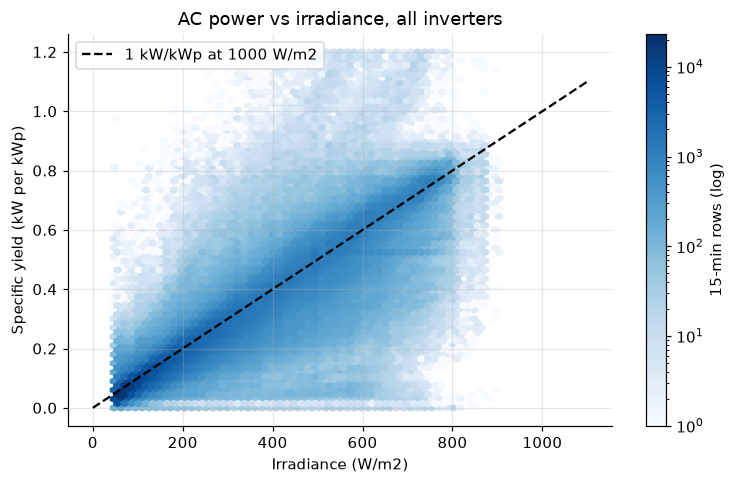

  saved figure eda_a1_power_vs_irradiance.png


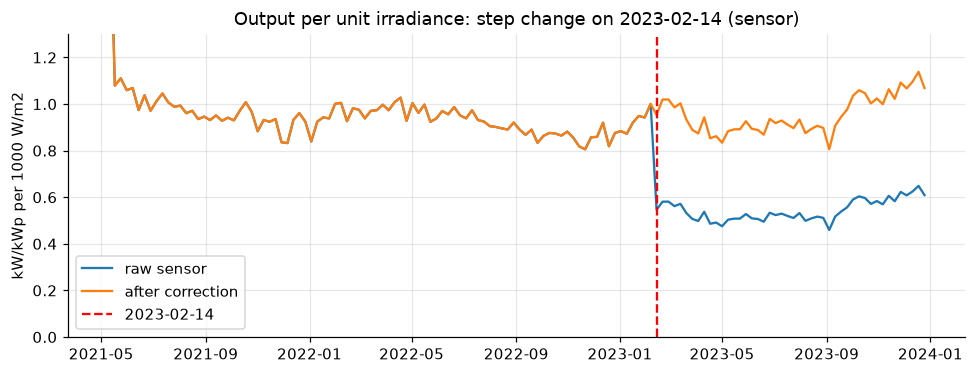

  saved figure eda_a1_sensor_change.png


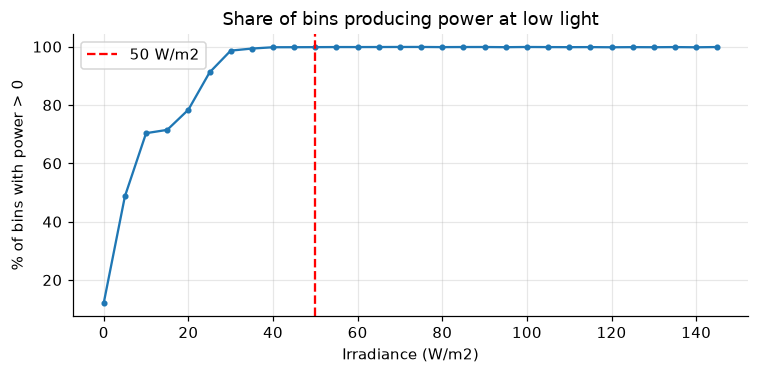

  saved figure eda_a1_night_threshold.png


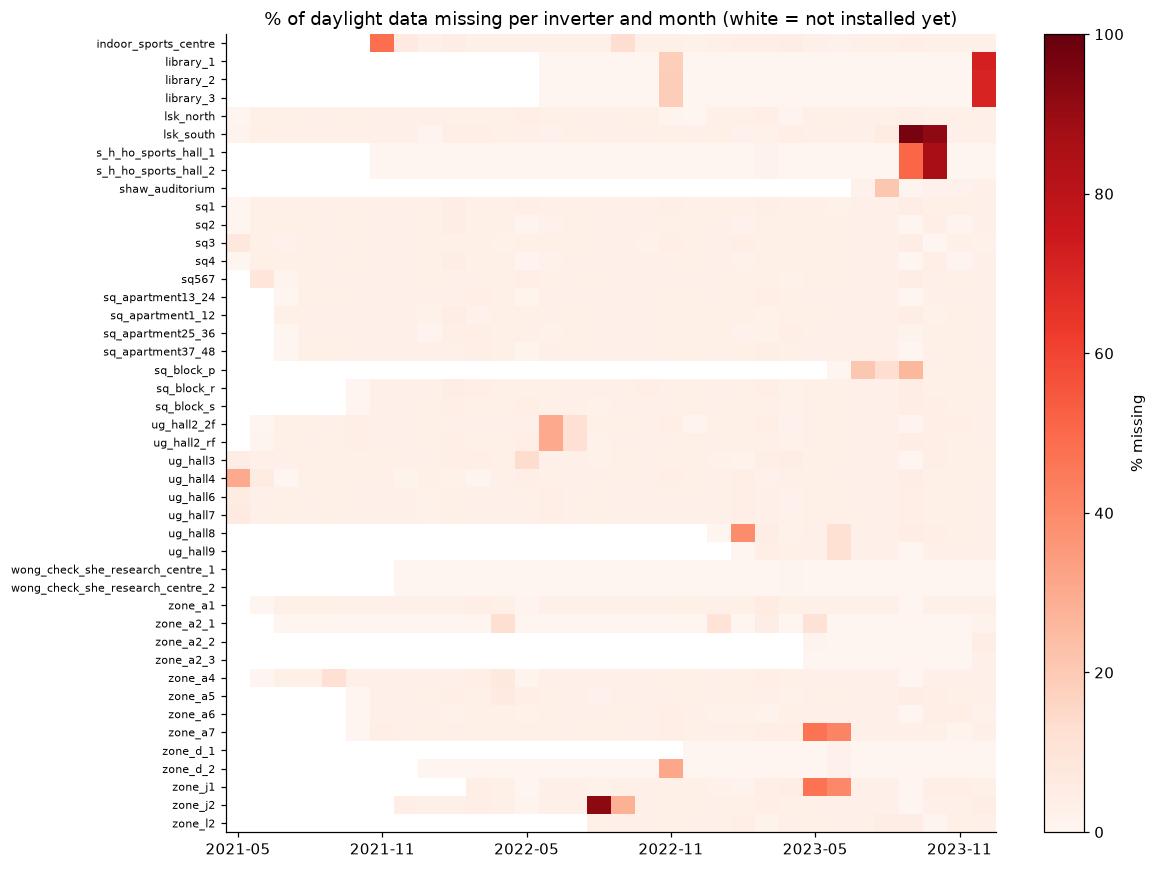

  saved figure eda_a1_gap_heatmap.png


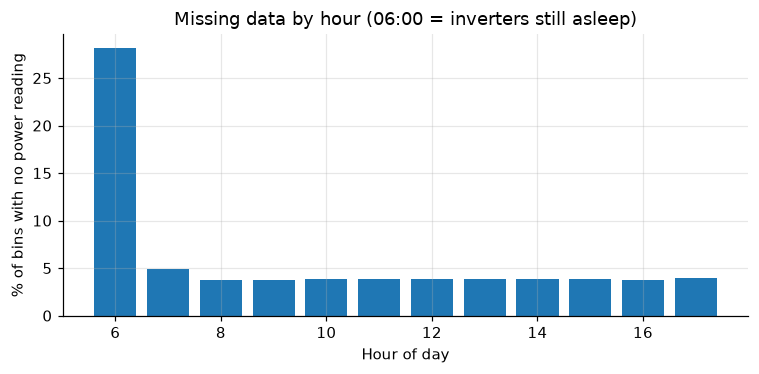

  saved figure eda_a1_missing_by_hour.png
A2


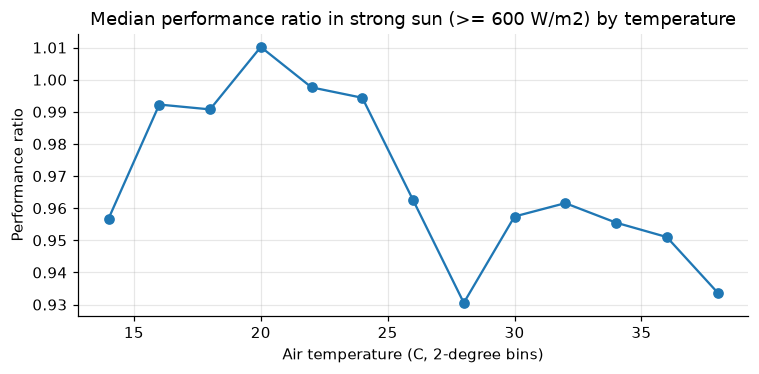

  saved figure eda_a2_temperature_effect.png
temp_c
14.0    0.957
16.0    0.992
18.0    0.991
20.0    1.010
22.0    0.998
24.0    0.994
26.0    0.963
28.0    0.931
30.0    0.957
32.0    0.962
34.0    0.955
36.0    0.951
38.0    0.934


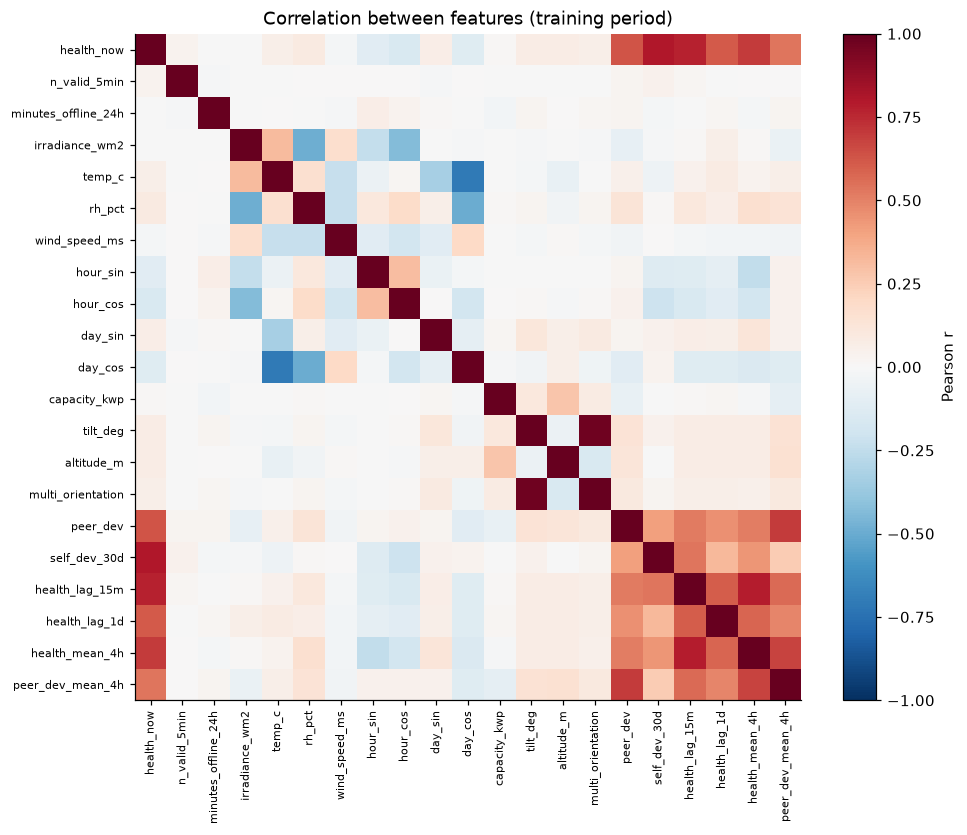

  saved figure eda_a2_feature_correlation.png
B1


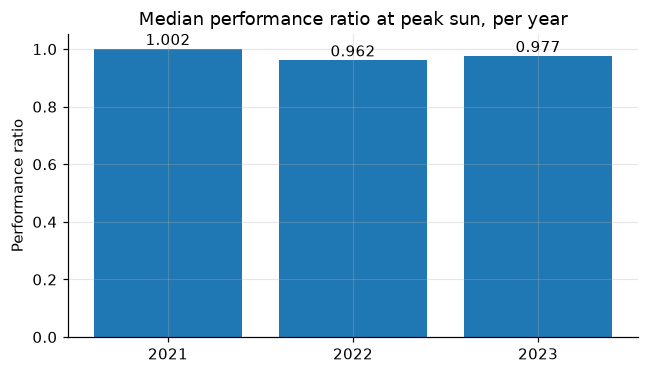

  saved figure eda_b1_degradation.png
time
2021    1.002
2022    0.962
2023    0.977


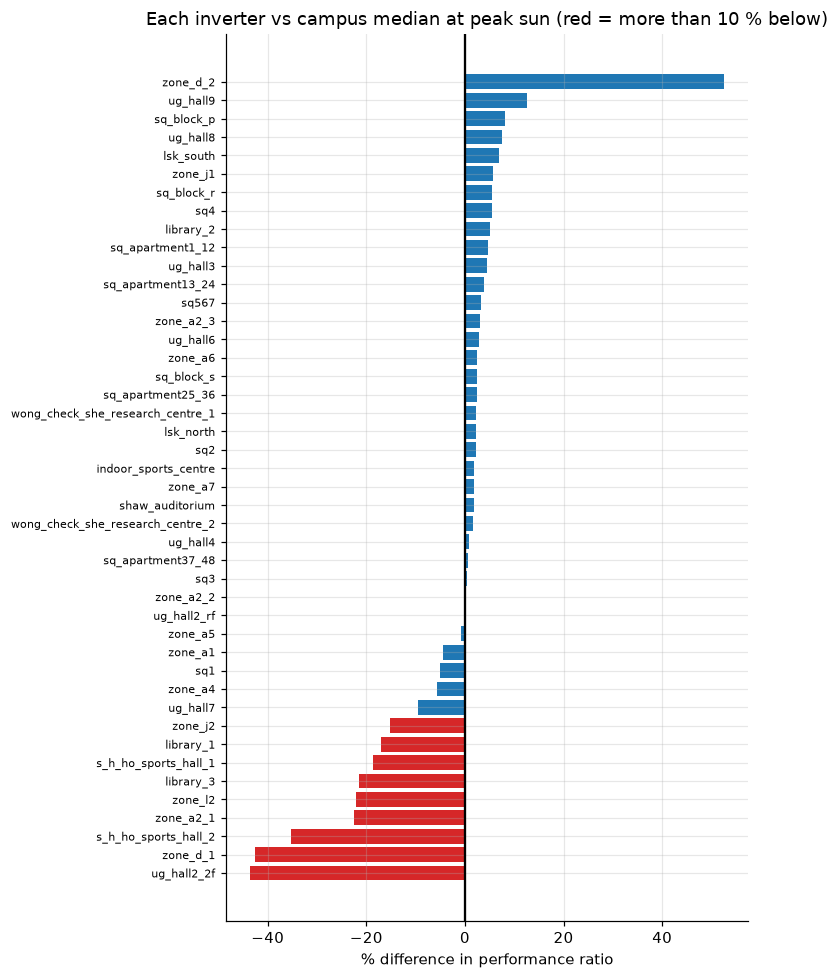

  saved figure eda_b1_underperformers.png
B2


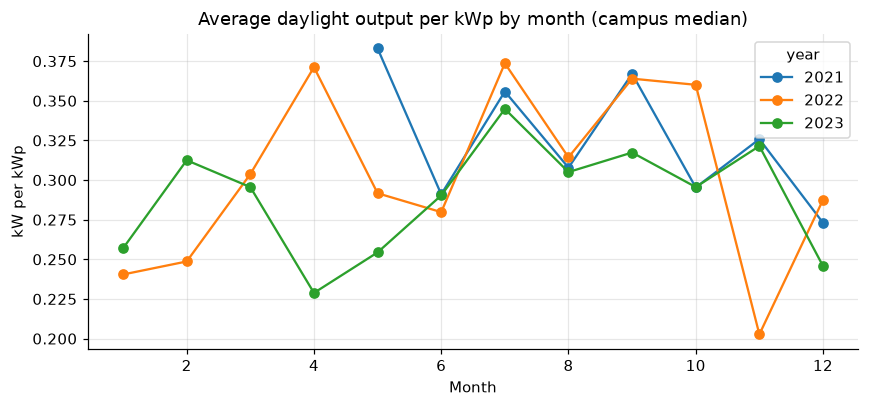

  saved figure eda_b2_seasonality.png


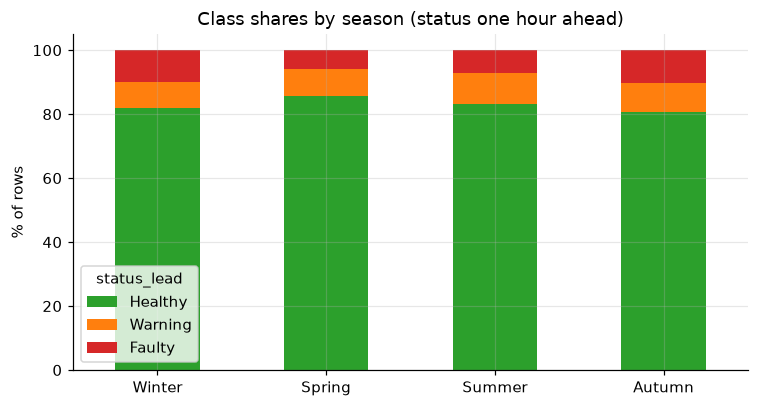

  saved figure eda_b2_class_distribution.png
status_lead  Healthy  Warning  Faulty
time                                 
Winter          81.8      8.2    10.1
Spring          85.8      8.2     6.0
Summer          83.2      9.8     7.0
Autumn          80.7      9.0    10.3


In [17]:
eda_main()

### Stages 4, 5 and 7: decision studies

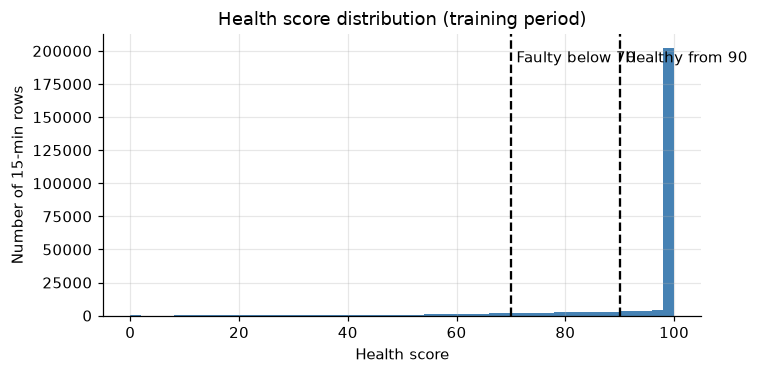

  saved figure target_health_distribution.png



study_imputation
imputation  rmse   mae    r2
    median 10.68 6.004 0.649
      mean 10.67 6.025 0.650

study_balancing
                         strategy  train_rows  macro_f1  faulty_recall  faulty_precision
                     no balancing      260819     0.547          0.595             0.745
           balanced class weights      260819     0.574          0.724             0.471
undersample Healthy (2 per other)      116940     0.605          0.655             0.619

study_thresholds
 faulty_below  healthy_from  faulty_pct  warning_pct  healthy_pct
           60            85         4.4          9.6         86.0
           60            90         4.4         12.4         83.2
           60            95         4.4         15.6         80.0
           65            85         5.7          8.3         86.0
           65            90         5.7         11.1         83.2
           65            95         5.7         14.3         80.0
           70            85         7.3   

In [18]:
studies_main()

### Stages 8-10: baselines and linear models (A1)

In [19]:
linear_main()


Persistence (regression)
              set   rows   rmse   mae    r2
            train 260819 12.125 5.074 0.271
              val 182731 13.074 6.325 0.474
             test 366110 12.350 5.248 0.399
test_before_14feb  34891 10.909 4.317 0.676
 test_after_14feb 331219 12.492 5.346 0.354
           unseen  37060 10.728 3.083 0.122



Majority class (classification)
              set   rows  macro_f1  faulty_recall  faulty_precision
            train 260819     0.306            0.0               0.0
              val 182731     0.295            0.0               0.0
             test 366110     0.302            0.0               0.0
test_before_14feb  34891     0.301            0.0               0.0
 test_after_14feb 331219     0.302            0.0               0.0
           unseen  37060     0.323            0.0               0.0



Health rule (classification)
              set   rows  macro_f1  faulty_recall  faulty_precision
            train 260819     0.562          0.524             0.481
              val 182731     0.595          0.648             0.547
             test 366110     0.592          0.601             0.564
test_before_14feb  34891     0.667          0.719             0.696
 test_after_14feb 331219     0.584          0.587             0.549
           unseen  37060     0.473          0.367             0.309



Peer rule (classification)
              set   rows  macro_f1  faulty_recall  faulty_precision
            train 260819     0.516          0.612             0.419
              val 182731     0.582          0.662             0.563
             test 366110     0.542          0.711             0.498
test_before_14feb  34891     0.609          0.812             0.619
 test_after_14feb 331219     0.534          0.699             0.485
           unseen  37060     0.459          0.362             0.313

Ridge (regression)


  best settings: {'model__alpha': 100}


              set   rows   rmse   mae    r2
            train 260819 10.001 5.140 0.504
              val 182731 10.680 6.004 0.649
             test 366110 10.174 5.351 0.592
test_before_14feb  34891  9.747 4.987 0.741
 test_after_14feb 331219 10.218 5.389 0.567
           unseen  37060  9.071 3.584 0.373

Logistic Regression (classification)


  best settings: {'model__C': 1}


              set   rows  macro_f1  faulty_recall  faulty_precision
            train 260819     0.556          0.610             0.457
              val 182731     0.574          0.724             0.471
             test 366110     0.572          0.706             0.500
test_before_14feb  34891     0.664          0.798             0.660
 test_after_14feb 331219     0.562          0.695             0.484
           unseen  37060     0.454          0.387             0.258


### Stages 9-10: Random Forest (A2)

In [20]:
rf_main()


Random Forest (regression)


  best settings: {'model__max_depth': 10, 'model__min_samples_leaf': 5}


              set   rows   rmse   mae    r2
            train 260819  8.218 4.196 0.665
              val 182731 10.361 5.718 0.670
             test 366110 10.445 5.407 0.570
test_before_14feb  34891  9.490 4.364 0.755
 test_after_14feb 331219 10.540 5.517 0.540
           unseen  37060  9.127 3.820 0.365

Random Forest (classification)


  best settings: {'model__max_depth': 20, 'model__min_samples_leaf': 5}


              set   rows  macro_f1  faulty_recall  faulty_precision
            train 260819     0.857          0.977             0.839
              val 182731     0.672          0.650             0.711
             test 366110     0.627          0.579             0.652
test_before_14feb  34891     0.713          0.738             0.742
 test_after_14feb 331219     0.617          0.560             0.639
           unseen  37060     0.489          0.336             0.378


### Stages 9-10: XGBoost (B1)


XGBoost (regression)


  best settings: {'model__learning_rate': 0.05, 'model__max_depth': 6}


              set   rows   rmse   mae    r2
            train 260819  7.637 3.839 0.711
              val 182731 10.732 5.821 0.646
             test 366110 10.690 5.610 0.549
test_before_14feb  34891  9.972 4.558 0.729
 test_after_14feb 331219 10.763 5.721 0.520
           unseen  37060  9.693 4.636 0.284

XGBoost (classification)


  best settings: {'model__learning_rate': 0.1, 'model__max_depth': 4}


              set   rows  macro_f1  faulty_recall  faulty_precision
            train 260819     0.634          0.712             0.576
              val 182731     0.623          0.630             0.607
             test 366110     0.580          0.578             0.549
test_before_14feb  34891     0.682          0.737             0.729
 test_after_14feb 331219     0.569          0.559             0.529
           unseen  37060     0.433          0.335             0.186


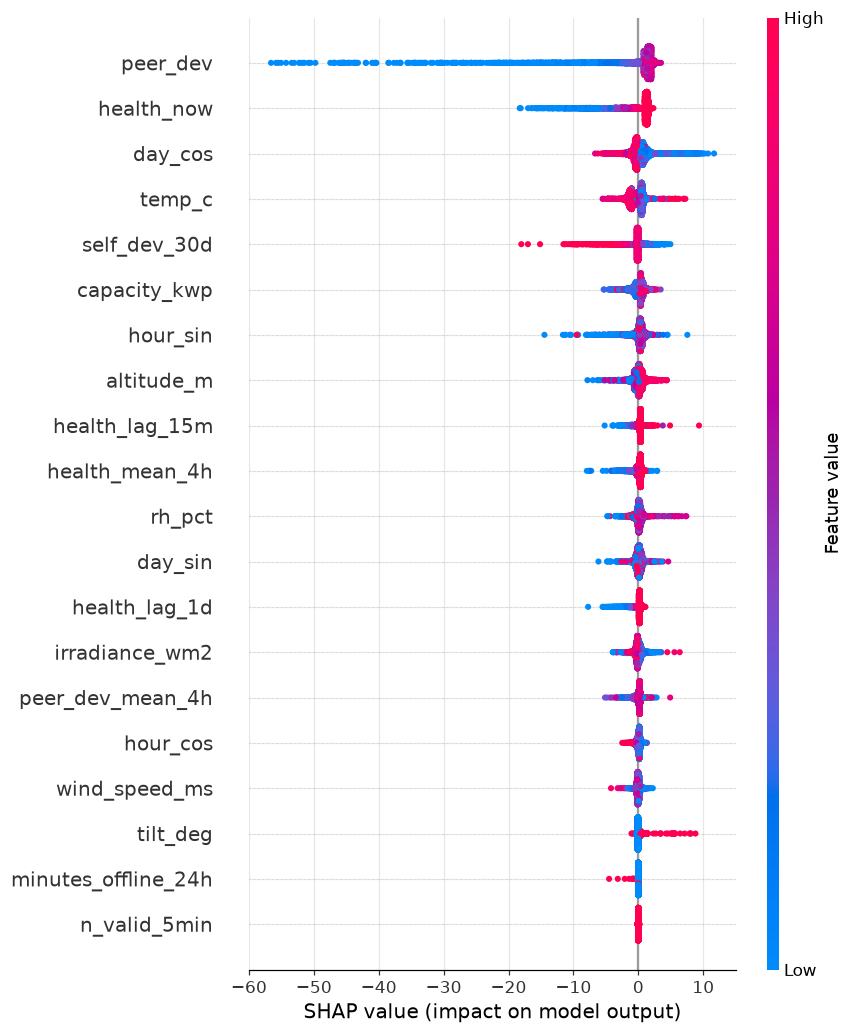

  saved figure xgb_shap_summary.png


In [21]:
xgb_main()

### Stages 9-10: MLP (B2)

In [22]:
mlp_main()


MLP (regression)


C:\Users\Veer\Documents\SEM_5\ML\ML_Assignment\InvertML\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


  best settings: {'model__alpha': 0.01, 'model__hidden_layer_sizes': (64, 32)}


              set   rows   rmse   mae     r2
            train 260819  8.105 4.194  0.674
              val 182731 11.404 5.916  0.600
             test 366110 10.835 5.570  0.537
test_before_14feb  34891 12.322 5.343  0.587
 test_after_14feb 331219 10.666 5.593  0.529
           unseen  37060 11.665 4.692 -0.038

MLP (classification)


  best settings: {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64, 32)}


              set   rows  macro_f1  faulty_recall  faulty_precision
            train 260819     0.605          0.677             0.509
              val 182731     0.608          0.681             0.525
             test 366110     0.560          0.593             0.486
test_before_14feb  34891     0.651          0.735             0.637
 test_after_14feb 331219     0.550          0.576             0.469
           unseen  37060     0.424          0.317             0.186


### Isolation Forest: HKUST injected faults and GPVS real faults

In [23]:
iforest_main()


HKUST injected faults
 contamination  n_estimators  detection_rate  false_alarm_rate  precision    f1
          0.01           100           0.473             0.021      0.041 0.076
          0.01           200           0.473             0.022      0.040 0.073
          0.02           100           0.490             0.042      0.022 0.043
          0.02           200           0.487             0.042      0.022 0.042
          0.05           100           0.639             0.086      0.014 0.028
          0.05           200           0.639             0.085      0.014 0.028
 set   rows  injected_rows  contamination  n_estimators  detection_rate  false_alarm_rate  precision    f1
test 366104            306           0.01           100           0.768             0.011      0.056 0.105



GPVS-Faults
 set  rows  fault_windows  detection_rate  false_alarm_rate  precision    f1
test   933            847            0.39               0.0        1.0 0.561
scenario  is_fault  flagged_share
     F0L         0          0.000
     F0M         0          0.000
     F1L         1          0.259
     F1M         1          0.873
     F2L         1          0.016
     F2M         1          0.862
     F3L         1          0.304
     F3M         1          0.094
     F4L         1          0.754
     F4M         1          0.015
     F5L         1          1.000
     F5M         1          1.000
     F6L         1          0.000
     F6M         1          0.062
     F7L         1          0.000
     F7M         1          0.046


### Stage 11: final comparison


compare_regression_rmse
set               val    test  test_before_14feb  test_after_14feb  unseen
model                                                                     
Random Forest  10.361  10.445              9.490            10.540   9.127
Ridge          10.680  10.174              9.747            10.218   9.071
XGBoost        10.732  10.690              9.972            10.763   9.693
MLP            11.404  10.835             12.322            10.666  11.665
Persistence    13.074  12.350             10.909            12.492  10.728

compare_classification_f1
set                    val   test  test_before_14feb  test_after_14feb  unseen
model                                                                         
Random Forest        0.672  0.627              0.713             0.617   0.489
XGBoost              0.623  0.580              0.682             0.569   0.433
MLP                  0.608  0.560              0.651             0.550   0.424
Health rule          0.595  

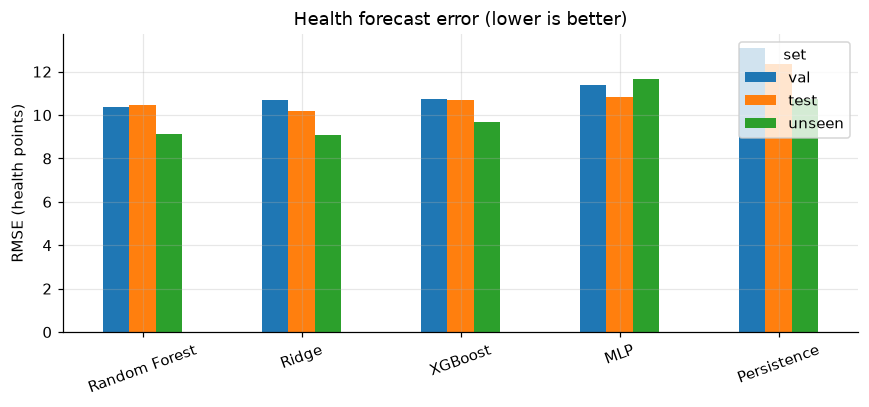

  saved figure compare_regression.png


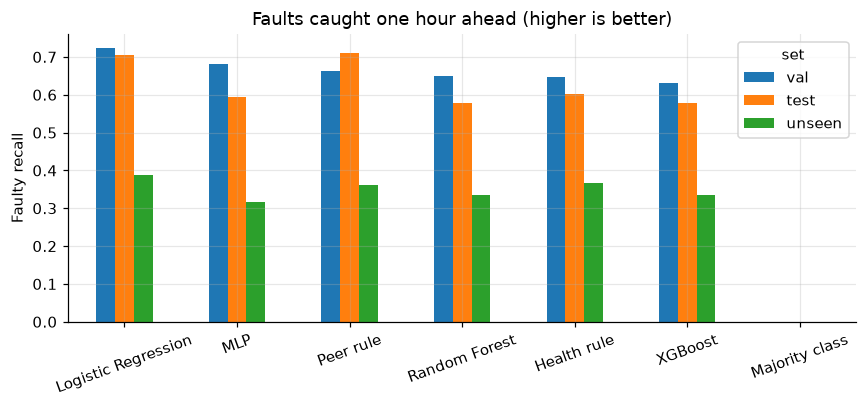

  saved figure compare_faulty_recall.png

best regressor (val RMSE): Random Forest
best classifier (val Faulty recall): Logistic Regression


In [24]:
compare_main()